## 03-问题分解（Decomposition）
- 要解决的问题：用户问题十分复杂，大模型需要推理分解多个步骤才能完整，但是有些大模型不具备推理能力
- 基本思路：可以用提示词工程中 CoT （Chain of Thought）策略，将复杂问题拆分为多个子问题，依次或并行同步解决所有子问题从而获取最终答案
    - 并行执行：将每个子任务抛给LLM得到一个答案，然后再让LLM把所有子任务的答案汇总起来
    - 串行执行：依次执行子任务，然后将前一个任务生成的答案作为后一个任务的提示词中的一部分

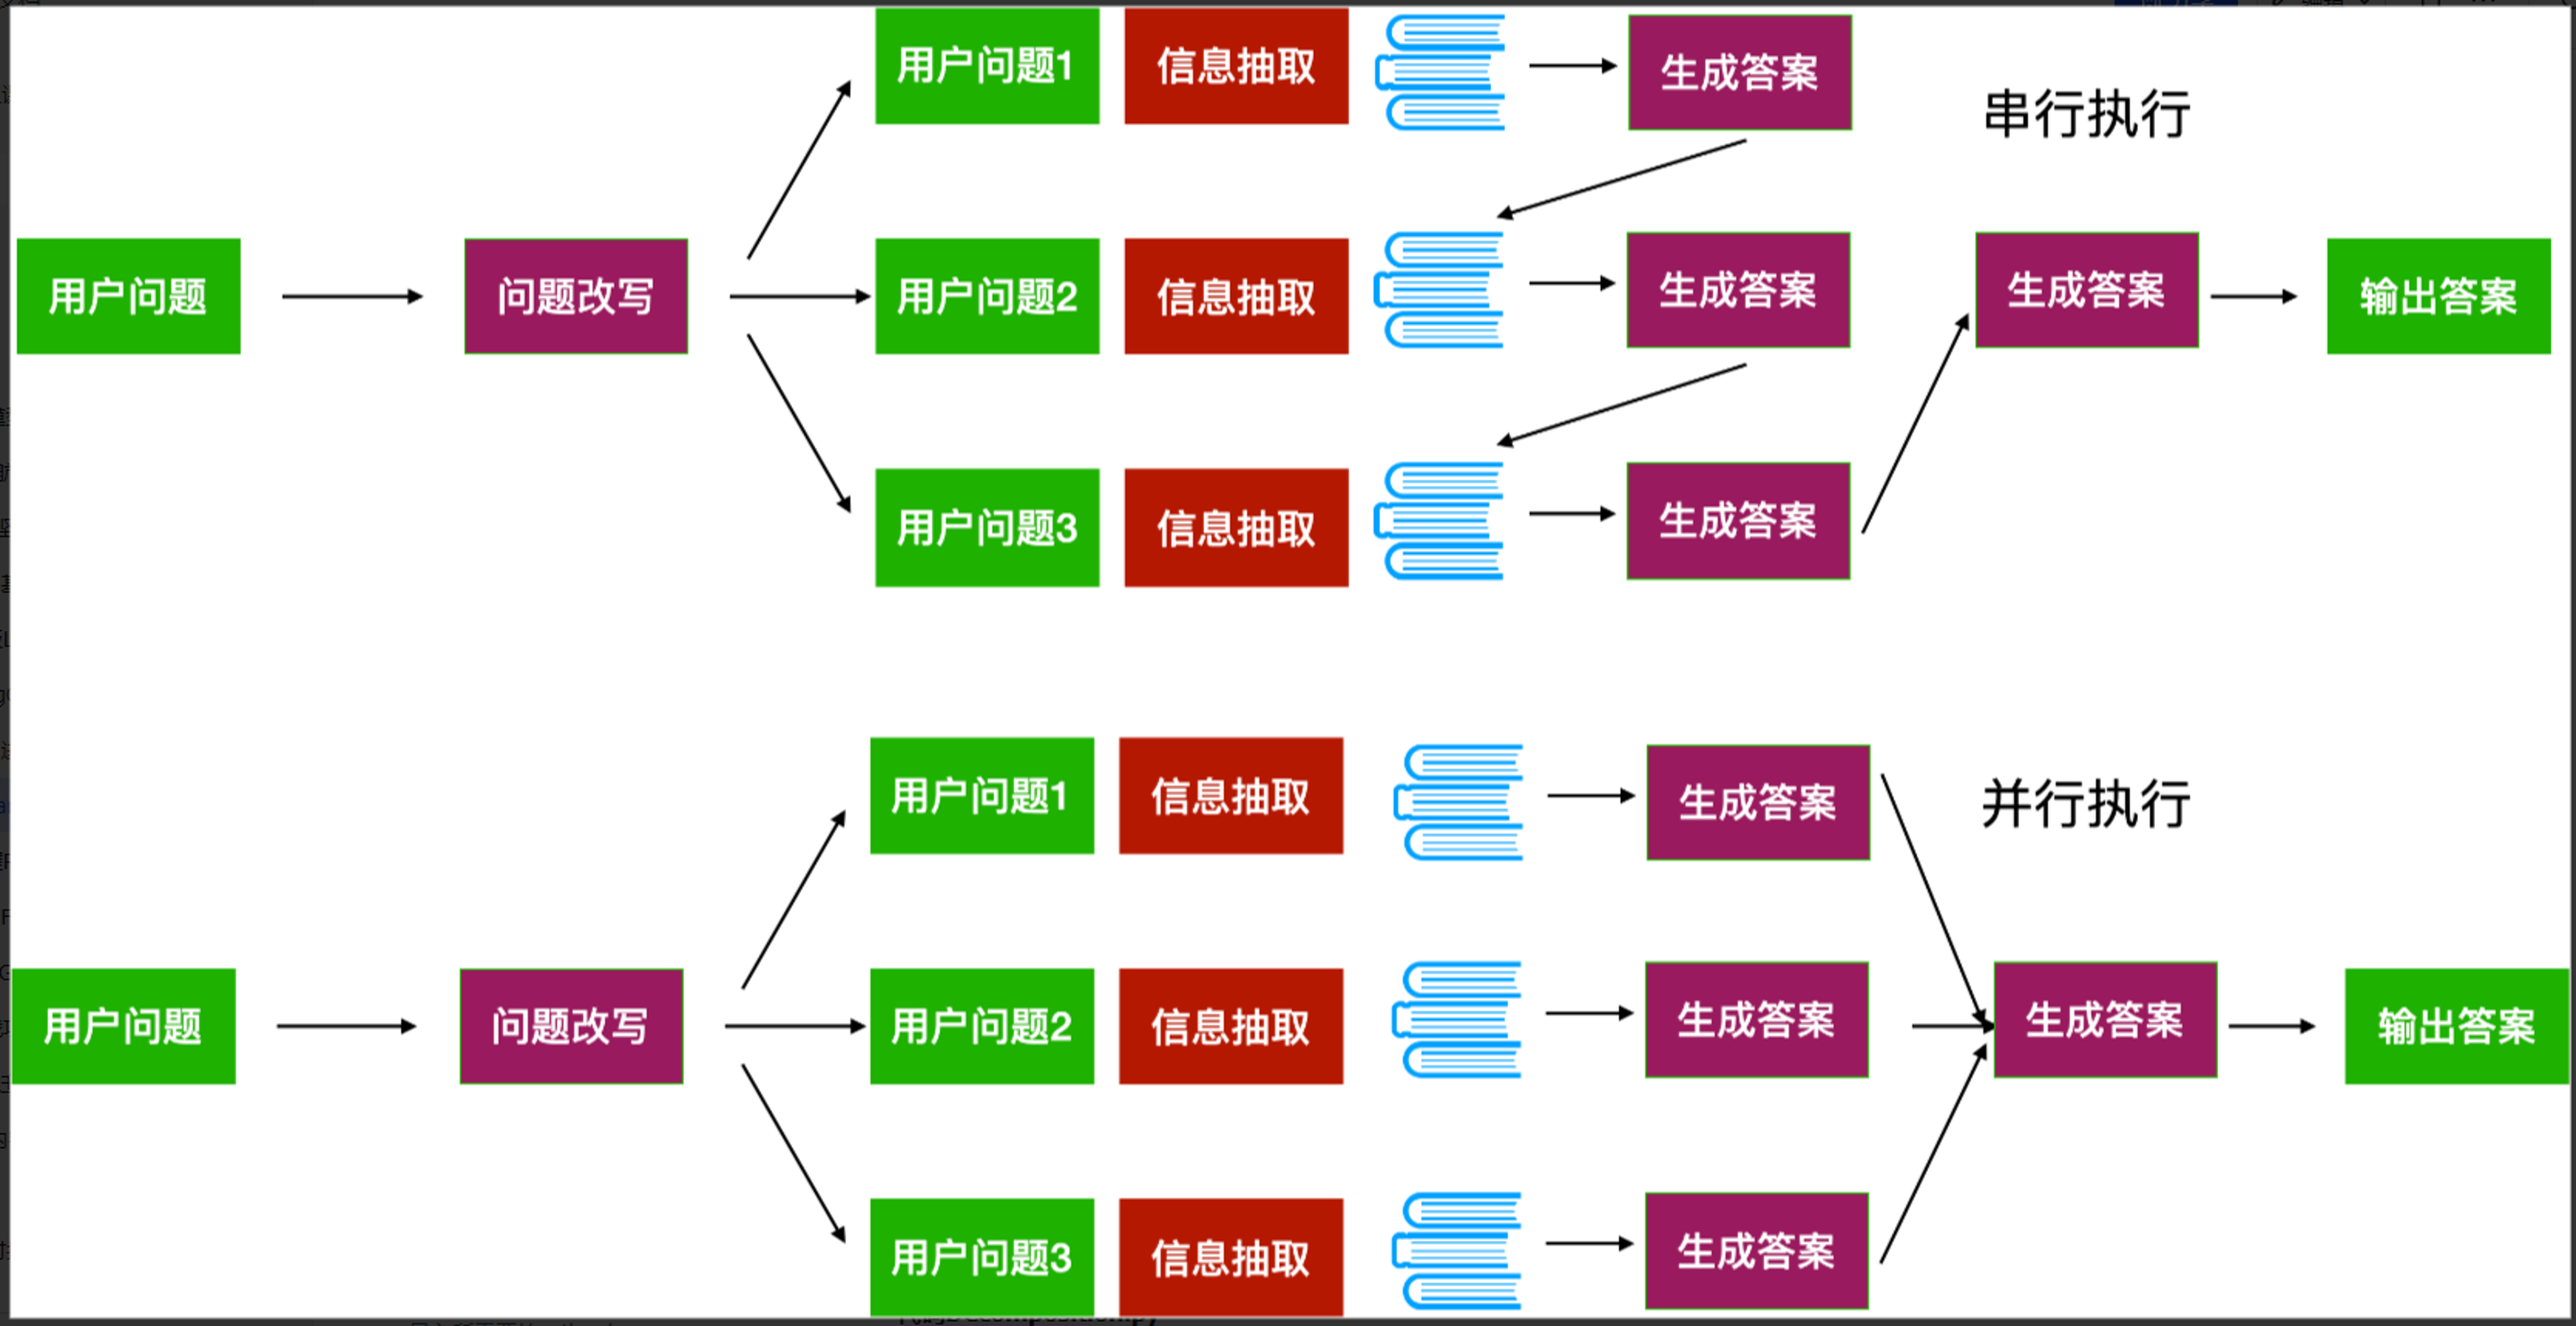

问题分解，实际生产中用提示词来实现的不多

#### 对话模型

In [1]:
import os
from langchain_openai import ChatOpenAI
llm = deepseek = ChatOpenAI(api_key=os.getenv("DEEPSEEK_API_KEY"), model="deepseek-v4-flash", base_url="https://api.deepseek.com")

#### 嵌入模型

In [2]:
from langchain_community.embeddings import DashScopeEmbeddings
embeddings_model = DashScopeEmbeddings(model="text-embedding-v4", dashscope_api_key=os.getenv("DASHSCOPE_API_KEY"))

# 通过本地ollama上运行的bge-m3做向量化, 使用需要关闭 代理/VPN
from langchain_ollama import OllamaEmbeddings
embeddings_model = OllamaEmbeddings(model="bge-m3")

#### 文档加载和分块

In [3]:
# 创建向量数据库，原始数据有三个chunk。
from langchain_core.documents import Document
documents = [
    Document(page_content="番茄炒蛋的食材：\n\n- 新鲜鸡蛋：3-4个（根据人数调整）\n- 番茄：2-3个中等大小\n- 盐：适量\n- 白糖：一小勺（可选，用于提鲜）\n- 食用油：适量\n- 葱花：少许（可选，用于增香）\n\n这些是最基本的材料，当然也可以根据个人口味添加其他调料或配料。"),
    Document(page_content="番茄炒蛋的步骤：鸡蛋打入碗中，加入少许盐，用筷子或打蛋器充分搅拌均匀；\n   - 番茄洗净后切成小块备用。\n\n3. **炒鸡蛋**：锅内倒入适量食用油加热至温热状态，然后将搅拌好的鸡蛋液缓缓倒入锅中。待鸡蛋凝固时轻轻翻动几下，让其受热均匀直至完全熟透，随后盛出备用。\n\n4. **炒番茄**：在同一锅里留下的底油中放入切好的番茄块，中小火慢慢翻炒至出汁，可根据个人口味加一点点白糖提鲜。\n\n5. **合炒**：当番茄炒至软烂并开始释放大量汤汁时，再把之前炒好的鸡蛋倒回锅里，快速与番茄混合均匀，同时加入适量的盐调味。如果喜欢的话还可以撒上一些葱花增加香气。\n\n6. **完成**：最后检查一下味道是否合适，确认无误后即可关火装盘享用美味的番茄炒蛋啦！"),
    Document(page_content="技巧与注意事项：1. **选材**：选择新鲜的鸡蛋和成熟的番茄。新鲜的食材是做好这道菜的基础。\n2. **打蛋液**：将鸡蛋打入碗中后加入少许盐（根据个人口味调整），然后充分搅拌均匀。这样做可以让蛋更加松软且味道更佳。\n3. **处理番茄**：番茄最好先用开水稍微焯一下皮，然后去皮切块。这样可以去除表皮的硬质部分，让番茄更容易入味，并且口感更好。\n4. **热锅冷油**：先用中小火把锅烧热，再倒入适量食用油，待油温五成热时下蛋液。这样的做法可以使蛋快速凝固形成漂亮的形状而不易粘锅。\n5. **分步烹饪**：通常建议先炒鸡蛋至半熟状态取出备用；接着利用剩下的底油继续翻炒番茄至出汁，最后再将之前炒好的鸡蛋倒回锅里与番茄混合均匀加热即可。\n6. **调味品**：除了基本的盐之外，还可以根据喜好添加少量糖来提鲜或者一点酱油增色添香。注意调味料不宜过多以免掩盖了食材本身的味道。\n7. **出锅前加葱花**：如果喜欢的话，在即将完成时撒上一些葱花不仅能增加菜品色泽还能增添香气。")
]

#### VectorStore

In [4]:
from langchain_community.vectorstores import Chroma
# 创建向量数据库
vectorstore = Chroma.from_documents(
    documents=documents,
    embedding=embeddings_model,
    collection_name="decomposition"
)
# 创建检索器，设置 top-k=1
retriever = vectorstore.as_retriever(search_kwargs={"k": 1})

In [5]:
# 格式化输出内容
def pretty_print_docs(docs):
    print(
        f"\n{'-' * 100}\n".join(
            [f"Document {i+1}:\n\n" + d.page_content for i, d in enumerate(docs)]
        )
    )

# 从实际来说，该问题的答案应该包括原材料、步骤，以及注意事项才算完整
print("-------------检索到的文档（拆解前）--------------")
pretty_print_docs(retriever.invoke("新手如何制作番茄炒蛋？"))

-------------检索到的文档（拆解前）--------------
Document 1:

番茄炒蛋的步骤：鸡蛋打入碗中，加入少许盐，用筷子或打蛋器充分搅拌均匀；
   - 番茄洗净后切成小块备用。

3. **炒鸡蛋**：锅内倒入适量食用油加热至温热状态，然后将搅拌好的鸡蛋液缓缓倒入锅中。待鸡蛋凝固时轻轻翻动几下，让其受热均匀直至完全熟透，随后盛出备用。

4. **炒番茄**：在同一锅里留下的底油中放入切好的番茄块，中小火慢慢翻炒至出汁，可根据个人口味加一点点白糖提鲜。

5. **合炒**：当番茄炒至软烂并开始释放大量汤汁时，再把之前炒好的鸡蛋倒回锅里，快速与番茄混合均匀，同时加入适量的盐调味。如果喜欢的话还可以撒上一些葱花增加香气。

6. **完成**：最后检查一下味道是否合适，确认无误后即可关火装盘享用美味的番茄炒蛋啦！


#### 问题分解链



将复杂问题拆解成多个子问题

In [6]:
from langchain_core.prompts import PromptTemplate
from langchain_classic.retrievers.multi_query import LineListOutputParser
print("开始问题拆解的处理=======================>")
template = """
    你是一名AI语言模型助理。你的任务是将输入问题分解成3个子问题，通过一个个解决这些子问题从而解决完整的问题。
    子问题需要在向量数据库中检索相关文档。通过分解用户问题生成子问题，你的目标是帮助用户克服基于距离的相似性搜索的一些局限性。
    请仅提供问题本身，每行一个，不要包含任何序号、引言或总结。

    示例：
    杀猪需要哪些工具？
    杀猪的具体步骤是什么？
    杀猪有哪些技巧？

    原始问题: {question}
"""

split_query_prompt = PromptTemplate(
    input_variables=["question"],
    template=template,
)
print("-------------测试大模型对问题的拆解，实际业务中可不用--------------")
# LineListOutputParser() 的作用是将模型输出的文本按换行符分割成字符串列表。
chain = split_query_prompt | llm | LineListOutputParser()
result = chain.invoke({"question":"新手如何制作番茄炒蛋？"})
print("问题拆解：", result)
print("-------------完成测试大模型对问题的拆解--------------")

开始问题拆解的处理=======================>
-------------测试大模型对问题的拆解，实际业务中可不用--------------
问题拆解： ['新手制作番茄炒蛋需要准备哪些食材和工具？', '番茄炒蛋的具体制作步骤是什么？', '新手做番茄炒蛋有哪些常见问题和技巧？']
-------------完成测试大模型对问题的拆解--------------


#### 子问题生成链

每个子问题生成答案

In [7]:
# 手动测试代码，测试对子问题的生成、获得子问题的答案
from langchain_core.output_parsers import StrOutputParser
sub_question_prompt = PromptTemplate(
    input_variables=["question", "sub_question", "documents"],
    template="""要解决主要问题{question}，需要先解决子问题{sub_question}。
    以下是为支持您的推理而提供的参考文档：{documents}。请直接给出当前子问题的答案。不需要额外内容。""",
)

resolve_chain = sub_question_prompt | llm | StrOutputParser()
# chain = split_query_prompt | llm | LineListOutputParser()
sub_questions = chain.invoke({"question":"新手如何制作番茄炒蛋？"})
print("问题拆解：", sub_questions)
print("-------------开始问题拆解的处理=======================>")
for i, sub_question in enumerate(sub_questions):
    print(f"-------------开始处理第{i+1}个子问题：", sub_question)
    print("检索到的文档是：",retriever.invoke(sub_question))
    print("-" * 60)
    answer = resolve_chain.invoke({"question": "新手如何制作番茄炒蛋？", "sub_question": sub_question, "documents": retriever.invoke(sub_question)})
    print(f"第{i+1}个子问题答案：", answer)
    print(f"-------------完成处理第{i+1}个子问题：", sub_question)

问题拆解： ['新手制作番茄炒蛋需要准备哪些食材和调料？', '番茄炒蛋的详细烹饪步骤是什么？', '新手做番茄炒蛋有哪些注意事项和技巧？']
-------------开始问题拆解的处理=======================>
-------------开始处理第1个子问题： 新手制作番茄炒蛋需要准备哪些食材和调料？
检索到的文档是： [Document(metadata={}, page_content='番茄炒蛋的食材：\n\n- 新鲜鸡蛋：3-4个（根据人数调整）\n- 番茄：2-3个中等大小\n- 盐：适量\n- 白糖：一小勺（可选，用于提鲜）\n- 食用油：适量\n- 葱花：少许（可选，用于增香）\n\n这些是最基本的材料，当然也可以根据个人口味添加其他调料或配料。')]
------------------------------------------------------------
第1个子问题答案： 新手制作番茄炒蛋需要准备：
- 新鲜鸡蛋：3-4个（根据人数调整）
- 番茄：2-3个中等大小
- 盐：适量
- 白糖：一小勺（可选，用于提鲜）
- 食用油：适量
- 葱花：少许（可选，用于增香）
-------------完成处理第1个子问题： 新手制作番茄炒蛋需要准备哪些食材和调料？
-------------开始处理第2个子问题： 番茄炒蛋的详细烹饪步骤是什么？
检索到的文档是： [Document(metadata={}, page_content='番茄炒蛋的步骤：鸡蛋打入碗中，加入少许盐，用筷子或打蛋器充分搅拌均匀；\n   - 番茄洗净后切成小块备用。\n\n3. **炒鸡蛋**：锅内倒入适量食用油加热至温热状态，然后将搅拌好的鸡蛋液缓缓倒入锅中。待鸡蛋凝固时轻轻翻动几下，让其受热均匀直至完全熟透，随后盛出备用。\n\n4. **炒番茄**：在同一锅里留下的底油中放入切好的番茄块，中小火慢慢翻炒至出汁，可根据个人口味加一点点白糖提鲜。\n\n5. **合炒**：当番茄炒至软烂并开始释放大量汤汁时，再把之前炒好的鸡蛋倒回锅里，快速与番茄混合均匀，同时加入适量的盐调味。如果喜欢的话还可以撒上一些葱花增加香气。\n\n6. **完成**：最后检查一下味道是否合适，确认无误后即可关火装盘享用美味的番茄炒蛋啦！')]
--------

自定义检索器

将对子问题的生成、获得子问题的答案组合起来，通过组合简化使用过程

In [8]:
from langchain_core.retrievers import BaseRetriever
from langchain_core.language_models import BaseLanguageModel
from langchain_core.prompts import BasePromptTemplate
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.callbacks import  CallbackManagerForRetrieverRun
from langchain_core.documents import Document
from langchain_core.runnables import Runnable,RunnableLambda

#自定义一个检索器，将对子问题的生成、获得子问题的答案组合起来，通过组合简化使用过程
class DecompositionQueryRetriever(BaseRetriever):
    # 向量数据库检索器
    retriever: BaseRetriever
    # 生成子问题链
    make_sub_chain: Runnable
    # 解决子问题链
    resolve_sub_chain: Runnable

    @classmethod
    def from_llm(
            cls,
            retriever: BaseRetriever,
            llm: BaseLanguageModel,
            prompt: BasePromptTemplate = split_query_prompt,
            sub_prompt: BasePromptTemplate = sub_question_prompt
        ) -> "DecompositionQueryRetriever":

        output_parser = LineListOutputParser()
        make_sub_chain = prompt | llm | output_parser
        resolve_sub_chain = sub_prompt | llm
        return cls(
            retriever=retriever,
            make_sub_chain=make_sub_chain,
            resolve_sub_chain=resolve_sub_chain,
        )

    #生成子问题
    def generate_queries(self, question: str) -> list[str]:
        response = self.make_sub_chain.invoke({"question": question})
        lines = response
        print(f"生成子问题: {lines}")
        return lines

    # 获得子问题答案
    def retrieve_documents(self, query: str, sub_queries: list[str]) -> list[Document]:
        sub_llm_chain = RunnableLambda(
            # 传入子问题，检索文档并回答
            lambda sub_query: self.resolve_sub_chain.invoke(
                {
                    "question": query,
                    "sub_question": sub_query,
                    "documents": [doc.page_content for doc in self.retriever.invoke(sub_query)]
                }
            )
        )
        # 批量执行所有的子问题(并行)
        responses = sub_llm_chain.batch(sub_queries)
        # 将子问题和答案合并作为解决主问题的文档
        documents = [
            Document(page_content=sub_query + "\n" + response.content)
            for sub_query, response in zip(sub_queries, responses)
        ]
        return documents


    def _get_relevant_documents(
            self,
            query: str,
            *,
            run_manager: CallbackManagerForRetrieverRun,
        ) -> list[Document]:
        # 生成子问题
        sub_queries = self.generate_queries(query)
        # 解决子问题
        documents = self.retrieve_documents(query, sub_queries)
        return documents

print("使用DecompositionQueryRetriever来分解问题------------>")
decompositionQueryRetriever = DecompositionQueryRetriever.from_llm(
    llm=llm,
    retriever=retriever,
)
decomposition_docs = decompositionQueryRetriever.invoke("番茄炒蛋怎么制作？")
print("-------------检索到的文档（拆解后）--------------")
pretty_print_docs(decomposition_docs)

# 创建prompt模板
template = """请根据以下文档回答问题:
### 文档:
{context}
### 问题:
{question}
"""

# 由模板生成prompt
prompt = ChatPromptTemplate.from_template(template)

final_chain = prompt | llm

print("-------------回答--------------")
question = "新手如何制作番茄炒蛋？"
response = final_chain.invoke({"context": [doc.page_content for doc in decomposition_docs], "question": question})
print(response.content)

使用DecompositionQueryRetriever来分解问题------------>
生成子问题: ['制作番茄炒蛋需要准备哪些食材和调味料？', '番茄炒蛋的具体烹饪步骤和火候如何掌握？', '番茄炒蛋有哪些常见技巧和注意事项？']
-------------检索到的文档（拆解后）--------------
Document 1:

制作番茄炒蛋需要准备哪些食材和调味料？
食材：新鲜鸡蛋3-4个、番茄2-3个中等大小、葱花少许（可选）。
调味料：盐适量、白糖一小勺（可选，用于提鲜）、食用油适量。
----------------------------------------------------------------------------------------------------
Document 2:

番茄炒蛋的具体烹饪步骤和火候如何掌握？
1. 鸡蛋打入碗中，加少许盐，用筷子或打蛋器充分搅匀；番茄洗净切小块备用。  
2. 锅中倒入适量食用油，加热至温热状态，缓缓倒入蛋液。待鸡蛋凝固时轻轻翻动几下，使其受热均匀至完全熟透，盛出备用。  
3. 同一锅留底油，放入番茄块，用中小火慢慢翻炒至出汁，可加少许白糖提鲜。  
4. 番茄炒至软烂并释放较多汤汁时，倒回炒好的鸡蛋，快速翻炒混合均匀，加适量盐调味，可撒葱花增香。  
5. 最后检查味道，合适后即可关火装盘。火候关键：炒鸡蛋用温热油、凝固后轻翻至熟；炒番茄用中小火慢炒出汁；合炒时快速混合，避免鸡蛋过老。
----------------------------------------------------------------------------------------------------
Document 3:

番茄炒蛋有哪些常见技巧和注意事项？
番茄炒蛋的常见技巧和注意事项：

1. 鸡蛋打散时加少许盐，充分搅拌均匀，炒出来更入味、口感更嫩。
2. 番茄洗净后切成小块，不要切得太大，便于炒出汁。
3. 炒鸡蛋时油温不宜过高，温热即可倒入蛋液；待鸡蛋凝固后轻轻翻动，熟透后盛出备用，避免炒老。
4. 炒番茄时用中小火慢慢翻炒至出汁，可根据口味加少量白糖提鲜、平衡酸味。
5. 番茄炒至软烂并释放汤汁后，再倒回炒好的鸡蛋，快速混合均匀，避免鸡蛋久炒变老。
6. 盐可在合炒时